# Практическая работа № 7
## Вариант 7 — активность по часам


In [2]:
%pip install pandas matplotlib seaborn

##  Загрузка данных


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

files = ["data/orders_2024_01.csv", "data/orders_2024_02.csv", "data/orders_2024_03.csv"]
orders = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
orders["order_datetime"] = pd.to_datetime(orders["order_datetime"])
orders["revenue"] = orders["price"] * orders["quantity"]
display(orders.head())
orders.info()
display(orders[["price", "quantity", "revenue"]].describe().round(2))

,order_id,user_id,order_datetime,product_id,price,quantity,status,revenue
0,1,1044,2024-01-03 18:39:26,26,14038.15,1,refunded,14038.15
1,2,1079,2024-01-03 17:45:43,16,9172.60,1,paid,9172.60
2,3,1041,2024-01-06 22:46:38,25,9035.26,2,paid,18070.52
3,4,1083,2024-01-08 21:03:51,9,15234.33,3,paid,45702.99
4,5,1068,2024-01-03 23:26:53,24,4134.38,2,paid,8268.76


<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        15000 non-null  int64         
 1   user_id         15000 non-null  int64         
 2   order_datetime  15000 non-null  datetime64[us]
 3   product_id      15000 non-null  int64         
 4   price           15000 non-null  float64       
 5   quantity        15000 non-null  int64         
 6   status          15000 non-null  str           
 7   revenue         15000 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(4), str(1)
memory usage: 879.0 KB


,price,quantity,revenue
count,15000.00,15000.00,15000.00
mean,10207.38,2.50,25636.24
std,5657.48,1.12,19330.33
min,300.26,1.00,308.21
25%,5304.96,2.00,10228.32
50%,10267.21,3.00,19665.64
75%,15050.53,4.00,37568.28
max,19998.96,4.00,79995.84


## 1 Группировка по order_hour
Сгруппировать данные по order_hour 

In [4]:
orders["order_hour"] = orders["order_datetime"].dt.hour
hourly = orders.groupby("order_hour").agg(
    orders_count=("order_id", "nunique"),
    revenue_sum=("revenue", "sum")
).reindex(range(24), fill_value=0)
display(hourly.round(2))

,orders_count,revenue_sum
order_hour,,
0,640,16876026.87
1,663,17205496.89
2,631,16291115.65
3,583,14888202.80
4,641,16693284.77
5,585,14503429.28
6,612,15181026.42
7,640,15456021.59
8,651,16545228.98


## 2 Линейный график количества заказов
Построить line chart количества заказов по часам.

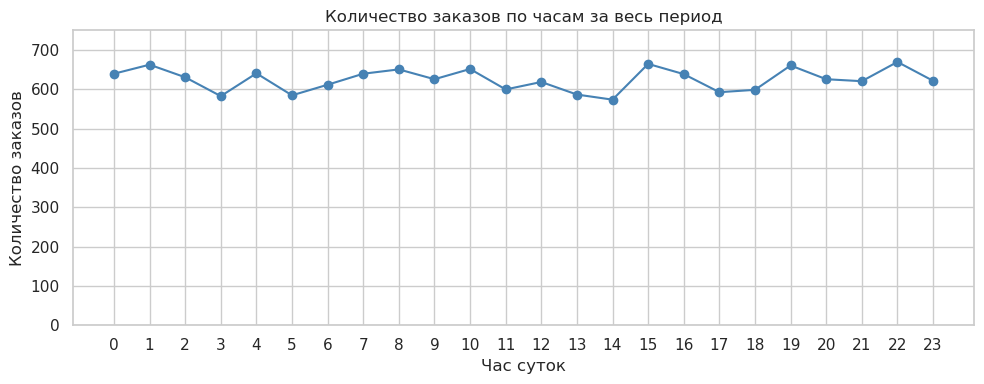

In [5]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 4))
plt.plot(hourly.index, hourly["orders_count"], marker="o", color="steelblue")
plt.title("Количество заказов по часам за весь период")
plt.xlabel("Час суток")
plt.ylabel("Количество заказов")
plt.xticks(range(24))
plt.ylim(0, hourly["orders_count"].max() * 1.12)
plt.tight_layout()
plt.show()

## 3 Пиковая активность и максимальная выручка
Если одинаковый максимум встречается в нескольких часах, показываем все эти часы.

In [6]:
peak_hours = hourly.index[hourly["orders_count"] == hourly["orders_count"].max()].tolist()
revenue_hours = hourly.index[hourly["revenue_sum"] == hourly["revenue_sum"].max()].tolist()
print("Часы пика количества заказов:", peak_hours)
print("Заказов в пиковом часу:", hourly["orders_count"].max())
print("Часы максимальной выручки:", revenue_hours)
print(f"Максимальная выручка за час: {hourly['revenue_sum'].max():,.2f}")
print("Минимум заказов за час:", hourly["orders_count"].min())
print(f"Среднее количество заказов на час суток: {hourly['orders_count'].mean():.2f}")

Часы пика количества заказов: [22]
Заказов в пиковом часу: 670
Часы максимальной выручки: [10]
Максимальная выручка за час: 17,830,751.64
Минимум заказов за час: 574
Среднее количество заказов на час суток: 625.00


## 4 Вывод о внутридневной активности
На предоставленных данных больше всего заказов приходится на **22:00–22:59 — 670 заказов**. Максимальная выручка приходится на **10:00–10:59 — 17 830 751,64** в денежных единицах исходных данных.

Минимальная активность — **14:00–14:59, 574 заказа**. В среднем на час суток приходится **625 заказов** за весь период. Диапазон 574–670 относительно узкий: активность распределена достаточно равномерно, без резкого вечернего или дневного всплеска.